<a href="https://colab.research.google.com/github/BrunaBitencourt05/Insights-na-TechGrow/blob/main/Insights_na_TechGrow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, roc_curve

In [ ]:
df = pd.read_csv("/content/Caso_Pratico_base_churn_saas.csv")

In [ ]:
df.describe()

,tempo_contrato_meses,logins_mes,tickets_suporte,valor_mensal,inadimplencia,qtd_funcionarios,uso_media_diaria_horas,churn
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
mean,9.690000,13.120000,2.570000,204.800000,0.420000,5.340000,1.729000,0.420000
std,6.107943,7.413174,2.370931,97.125141,0.496045,3.736849,1.045461,0.496045
min,1.000000,2.000000,0.000000,100.000000,0.000000,1.000000,0.200000,0.000000
25%,5.000000,6.000000,1.000000,115.000000,0.000000,2.000000,0.800000,0.000000
50%,9.000000,12.500000,1.500000,205.000000,0.000000,5.000000,1.650000,0.000000
75%,13.000000,19.000000,5.000000,240.000000,1.000000,7.000000,2.700000,1.000000
max,30.000000,29.000000,8.000000,400.000000,1.000000,15.000000,4.000000,1.000000


In [ ]:
df.isnull().sum()

,0
id_cliente,0
tempo_contrato_meses,0
plano,0
regiao,0
logins_mes,0
tickets_suporte,0
valor_mensal,0
inadimplencia,0
qtd_funcionarios,0
uso_media_diaria_horas,0


/tmp/ipykernel_4603/3383346277.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='churn', palette='Set2')


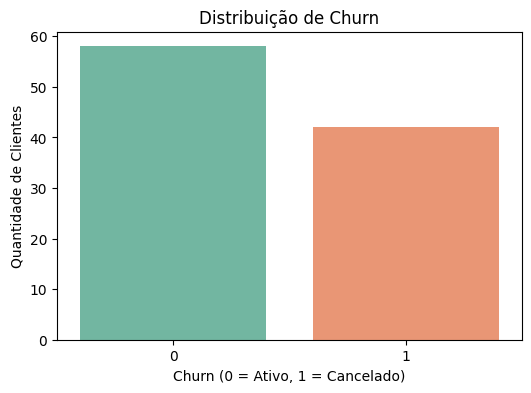

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='churn', palette='Set2')
plt.title('Distribuição de Churn')
plt.xlabel('Churn (0 = Ativo, 1 = Cancelado)')
plt.ylabel('Quantidade de Clientes')
plt.show()

/tmp/ipykernel_4603/2686524131.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='churn', y='tempo_contrato_meses', palette='Set2')


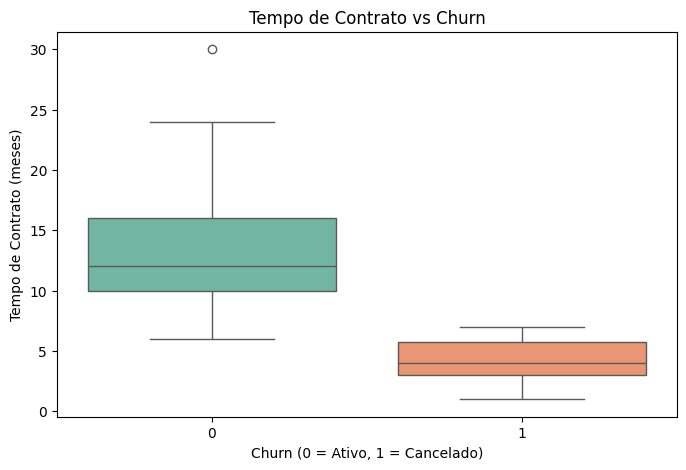

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='churn', y='tempo_contrato_meses', palette='Set2')
plt.title('Tempo de Contrato vs Churn')
plt.xlabel('Churn (0 = Ativo, 1 = Cancelado)')
plt.ylabel('Tempo de Contrato (meses)')
plt.show()

In [ ]:
# Verifica quais colunas são do tipo objeto (texto/categóricas)
colunas_categoricas = df.select_dtypes(include=['object']).columns
df_tratado = pd.get_dummies(df, columns=colunas_categoricas, drop_first=True)

In [ ]:
df_tratado.head()

,tempo_contrato_meses,logins_mes,tickets_suporte,valor_mensal,inadimplencia,qtd_funcionarios,uso_media_diaria_horas,churn,plano_Intermediário,plano_Premium,regiao_Nordeste,regiao_Sudeste,regiao_Sul
0,12,15,2,120,0,3,1.8,0,False,False,False,True,False
1,3,4,6,350,1,8,0.5,1,False,True,False,False,True
2,8,10,1,210,0,5,1.2,0,True,False,False,True,False
3,24,25,0,370,0,12,3.5,0,False,True,False,False,False
4,6,6,4,130,1,2,0.9,1,False,False,True,False,False


In [ ]:
colunas_numericas = ['tempo_contrato_meses', 'logins_mes', 'tickets_suporte', 'valor_mensal', 'qtd_funcionarios', 'uso_media_diaria_horas']


In [ ]:
scaler = StandardScaler()
df_tratado[colunas_numericas] = scaler.fit_transform(df_tratado[colunas_numericas])

In [ ]:
df_tratado.head()

,tempo_contrato_meses,logins_mes,tickets_suporte,valor_mensal,inadimplencia,qtd_funcionarios,uso_media_diaria_horas,churn,id_cliente_C002,id_cliente_C003,...,id_cliente_C096,id_cliente_C097,id_cliente_C098,id_cliente_C099,id_cliente_C100,plano_Intermediário,plano_Premium,regiao_Nordeste,regiao_Sudeste,regiao_Sul
0,0.380101,0.254880,-0.241623,-0.877499,0,-0.629351,0.068255,0,False,False,...,False,False,False,False,False,False,False,False,True,False
1,-1.100813,-1.236440,1.453977,1.502510,1,0.715416,-1.181480,1,True,False,...,False,False,False,False,False,False,True,False,False,True
2,-0.278083,-0.422993,-0.665523,0.053809,0,-0.091444,-0.508546,0,False,True,...,False,False,False,False,False,True,False,False,True,False
3,2.354654,1.610626,-1.089423,1.709467,0,1.791229,1.702523,0,False,False,...,False,False,False,False,False,False,True,False,False,False
4,-0.607175,-0.965291,0.606177,-0.774020,1,-0.898304,-0.796946,1,False,False,...,False,False,False,False,False,False,False,True,False,False


In [ ]:
correlacao = df_tratado.corr()

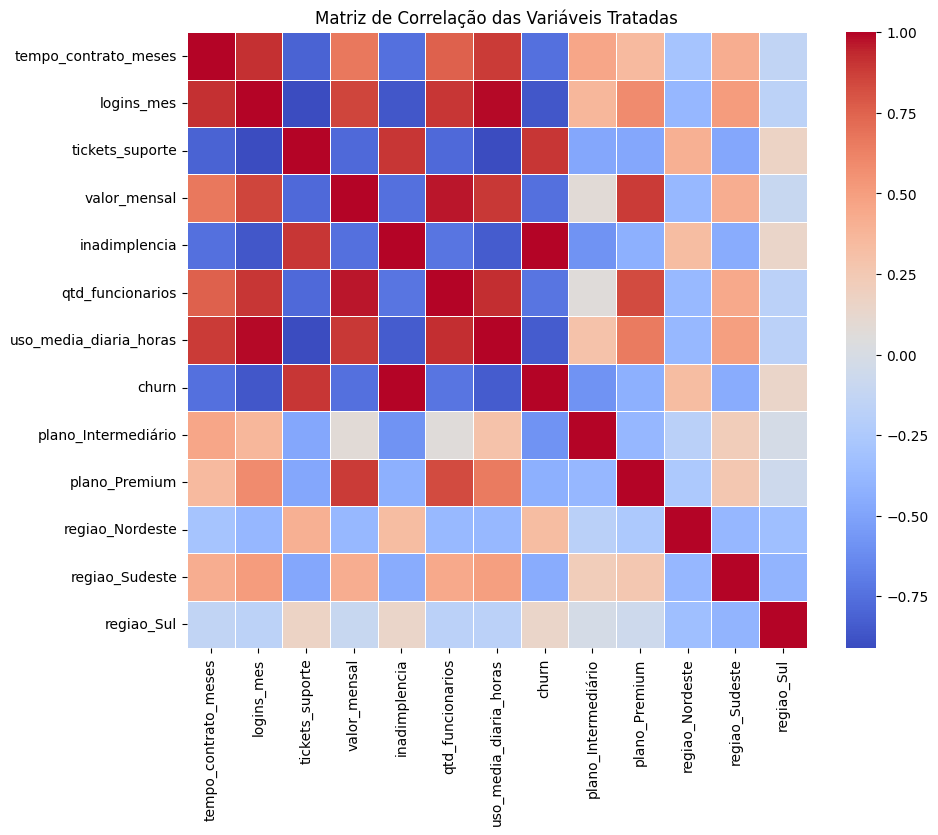

In [ ]:
plt.figure(figsize=(10, 8))
correlacao = df_tratado.corr()
sns.heatmap(correlacao, annot=False, cmap='coolwarm', linewidths=0.5) # Usar annot=False ajuda se houver muitas colunas
plt.title('Matriz de Correlação das Variáveis Tratadas')
plt.show()

In [ ]:
# Define a variável-alvo (target) e as features (X)
X = df_tratado.drop(columns=['churn'])
y = df_tratado['churn']

In [ ]:
# Separa em 70% para treino e 30% para teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Tamanho do treino: {X_train.shape[0]} linhas")
print(f"Tamanho do teste: {X_test.shape[0]} linhas")

Tamanho do treino: 70 linhas
Tamanho do teste: 30 linhas


In [ ]:
# 1. Baseline: Regressão Logística
modelo_lr = LogisticRegression(random_state=42)
modelo_lr.fit(X_train, y_train)

# 2. Random Forest
modelo_rf = RandomForestClassifier(random_state=42)
modelo_rf.fit(X_train, y_train)

# 3. XGBoost
modelo_xgb = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss')
modelo_xgb.fit(X_train, y_train)

print("Modelos treinados com sucesso!")

Modelos treinados com sucesso!


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:26:22] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [ ]:
# Dicionário para guardar os modelos para a avaliação
modelos = {
    "Regressão Logística": modelo_lr,
    "Random Forest": modelo_rf,
    "XGBoost": modelo_xgb
}
plt.figure(figsize=(12, 5))

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

In [ ]:
# Subplot 1: Matrizes de Confusão e Relatórios
for i, (nome, modelo) in enumerate(modelos.items()):
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    print(f"=== {nome} ===")
    print(classification_report(y_test, y_pred))
    print(f"ROC AUC: {roc_auc_score(y_test, y_prob):.4f}\n")

=== Regressão Logística ===
              precision    recall  f1-score   support

           0       1.00      0.88      0.94        17
           1       0.87      1.00      0.93        13

    accuracy                           0.93        30
   macro avg       0.93      0.94      0.93        30
weighted avg       0.94      0.93      0.93        30

ROC AUC: 1.0000

=== Random Forest ===
              precision    recall  f1-score   support

           0       1.00      0.88      0.94        17
           1       0.87      1.00      0.93        13

    accuracy                           0.93        30
   macro avg       0.93      0.94      0.93        30
weighted avg       0.94      0.93      0.93        30

ROC AUC: 1.0000

=== XGBoost ===
              precision    recall  f1-score   support

           0       1.00      0.82      0.90        17
           1       0.81      1.00      0.90        13

    accuracy                           0.90        30
   macro avg       0.91     

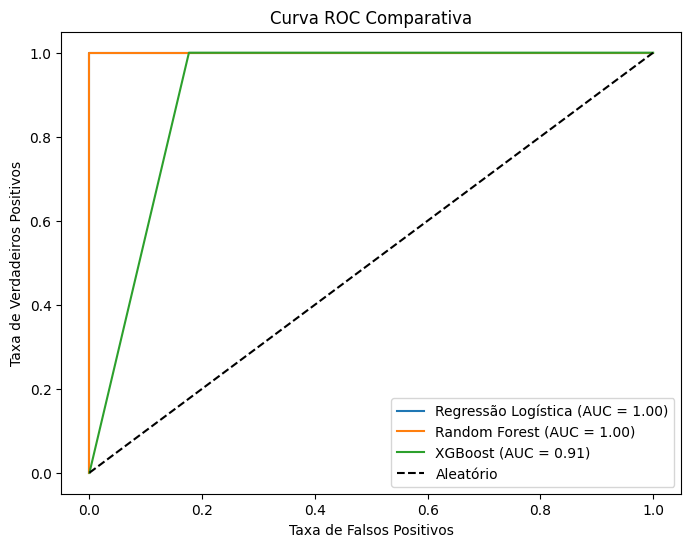

In [ ]:
# Subplot 2: Curva ROC Comparativa
plt.figure(figsize=(8, 6))
for nome, modelo in modelos.items():
    y_prob = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.2f})")

plt.plot([0, 1], [0, 1], 'k--', label='Aleatório')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC Comparativa')
plt.legend()
plt.show()

In [ ]:
importancia = pd.DataFrame({
    'Variável': X.columns,
    'Importância': modelo_rf.feature_importances_
}).sort_values(by='Importância', ascending=False)

print(importancia.head(10))

                  Variável  Importância
1               logins_mes     0.214129
2          tickets_suporte     0.181711
4            inadimplencia     0.181081
6   uso_media_diaria_horas     0.177864
0     tempo_contrato_meses     0.118604
3             valor_mensal     0.063285
5         qtd_funcionarios     0.043875
7      plano_Intermediário     0.014499
8            plano_Premium     0.004443
10          regiao_Sudeste     0.000510
